# VGG16 pipeline: myeloma cell classification (Google Colab)

One model, every step spelled out in order. **Runtime > Change runtime type > T4 GPU** before you start.

| Step | What happens |
|---|---|
| 0 | Check the GPU, import libraries, fix the random seed |
| 1 | Connect Google Drive and find your dataset folder |
| 2 | Copy the dataset to Colab's fast local disk and look inside |
| 3 | Work out what format the dataset is in |
| 4 | Build the table of (image, label) |
| 5 | Look at the pictures and fix the label meaning |
| 6 | Split into train / validation / test |
| 7 | Class weights |
| 8 | Data pipeline + augmentation |
| 9 | Build VGG16 |
| 10 | Train phase 1 (new head only) |
| 11 | Train phase 2 (fine-tune last conv block) |
| 12 | Learning curves |
| 13 | Test-set evaluation |
| 14 | Look at the mistakes |
| 15 | Save everything to Drive |

## Step 0: GPU, imports, seed
We check Colab gave us a GPU (training VGG16 on CPU takes hours), import everything we need once, and fix the random seed so a re-run gives the same split and similar results.

In [ ]:
import os
from collections import Counter

root = "/content/drive/MyDrive/PlasmaCells"
MAX_LINES, lines = 400, 0
csvs = []

for d, subs, files in os.walk(root):
    subs.sort()
    depth = d[len(root):].count(os.sep)
    exts = dict(Counter(os.path.splitext(f)[1].lower() for f in files))
    print("  " * depth + os.path.basename(d) + "/",
          f"[{len(subs)} subfolders, {len(files)} files]", exts, sorted(files)[:3])
    csvs += [os.path.join(d, f) for f in files if f.lower().endswith(".csv")]
    lines += 1
    if lines >= MAX_LINES:
        print("... stopped at", MAX_LINES, "folders")
        break

import pandas as pd
for c in csvs[:5]:
    print("\n", os.path.relpath(c, root))
    print(pd.read_csv(c).head(3).to_string())


PlasmaCells/ [1 subfolders, 0 files] {} []
  PCMMD Plasma Cells for Multiple Myeloma Diagnosis/ [1 subfolders, 0 files] {} []
    data/ [2 subfolders, 0 files] {} []
      detection/ [2 subfolders, 11 files] {'.yaml': 6, '.txt': 5} ['mieloma_final.yaml', 'mieloma_fold_1.yaml', 'mieloma_fold_2.yaml']
        patients/ [10 subfolders, 1 files] {'.csv': 1} ['diagnosis.csv']
          patient 01/ [2 subfolders, 0 files] {} []
            images/ [0 subfolders, 34 files] {'.jpg': 34} ['IMG_20240608_102819.jpg', 'IMG_20240608_102913.jpg', 'IMG_20240608_102917.jpg']
            labels/ [0 subfolders, 34 files] {'.txt': 34} ['IMG_20240608_102819.txt', 'IMG_20240608_102913.txt', 'IMG_20240608_102917.txt']
          patient 02/ [2 subfolders, 0 files] {} []
            images/ [0 subfolders, 32 files] {'.jpg': 32} ['IMG_20240608_102931.jpg', 'IMG_20240608_102938.jpg', 'IMG_20240608_102954.jpg']
            labels/ [0 subfolders, 32 files] {'.txt': 32} ['IMG_20240608_102931.txt', 'IMG_20240608_10

In [8]:
import os, glob, shutil, zipfile, random, time, json
from collections import Counter
from pathlib import Path
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score, roc_curve,
                             accuracy_score, precision_score, recall_score, f1_score)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Step 1: Connect Google Drive and find the dataset folder
This gives Colab access to your Drive. Then we list the top of *My Drive* so you can see the exact name of the dataset folder. I can't see your Drive, so **you** copy that name into `DRIVE_FOLDER`.

In [9]:
from google.colab import drive
drive.mount("/content/drive")
print(os.listdir("/content/drive/MyDrive"))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['Classroom', '202208051508351000.jpg', 'CamScanner 06-10-2022 18.34.gdoc', 'Day 7 and Day 8 note.gdoc', '1efa2875-6151-4148-bbb3-afd91af0c69d.jpg', '17145f06-10a9-4bed-98eb-8d83e9fdf702.jpg', 'Untitled video - Made with Clipchamp.mp4', 'web workshop', 'SENALI WEB', 'python practicals 11.11', 'python', 'Combined Maths New Syllabus 2017.gdoc', 'Mechanics tute 01 (Mahen Jecob) .pdf', 'what i did today.gsheet', '20230818_191816.jpg', 'Rec 0025.mp4', 'programming note.gdoc', 'Colab Notebooks', 'image_carsRaIWx (1).jpg', 'image_bZBNmJy34P (1).jpg', 'image_7nCfxbTqLv (1).jpg', 'image_DrXxFLnKxN (1).jpg', 'image_E2rrHwZj_U (1).jpg', 'image_GPI9JKc-Jo (1).jpg', 'image_nocD5ASfb2 (1).jpg', 'image_p7x0P52QRc (1).jpg', 'image_PgtQJzO759.jpg', 'image_7nCfxbTqLv.jpg', 'image_carsRaIWx.jpg', 'image_bZBNmJy34P.jpg', 'image_SX7ru0WjY0.jpg', 'image_TUbXqD70O1.jpg', 'image_RbZ

In [ ]:
DRIVE_FOLDER = "/content/drive/MyDrive/PlasmaCells"
assert os.path.isdir(DRIVE_FOLDER), "Folder not found: fix DRIVE_FOLDER"

## Step 2: Copy to local disk and look inside
Reading thousands of small files straight from Drive is slow, so we copy everything to `/content/data` once. If the folder contains `.zip` files we unzip them. Then we print what is in there: how many images, how many `.txt` files, and the first few folder names.

In [10]:
LOCAL = "/content/data"
if not os.path.isdir(LOCAL):
    shutil.copytree(DRIVE_FOLDER, LOCAL)
    for z in glob.glob(f"{LOCAL}/**/*.zip", recursive=True):
        print("unzipping", z)
        with zipfile.ZipFile(z) as f:
            f.extractall(os.path.join(os.path.dirname(z), Path(z).stem + "_unzipped"))

IMG_EXT = (".bmp", ".jpg", ".jpeg", ".png", ".tif", ".tiff")
imgs = [p for p in glob.glob(f"{LOCAL}/**/*", recursive=True) if p.lower().endswith(IMG_EXT)]
txts = [p for p in glob.glob(f"{LOCAL}/**/*.txt", recursive=True)]
csvs = [p for p in glob.glob(f"{LOCAL}/**/*.csv", recursive=True)]
print("images:", len(imgs), "| txt files:", len(txts), "| csv files:", [os.path.basename(c) for c in csvs])
print("\nfolders that hold images:")
for d, n in Counter(os.path.dirname(p) for p in imgs).most_common(15):
    print(f"{n:6d}  {os.path.relpath(d, LOCAL)}")

images: 4406 | txt files: 862 | csv files: ['diagnosis.csv']

folders that hold images:
  1932  PCMMD Plasma Cells for Multiple Myeloma Diagnosis/data/segmentation/non-plasma cells/images
  1616  PCMMD Plasma Cells for Multiple Myeloma Diagnosis/data/segmentation/plasma cells/images
   513  PCMMD Plasma Cells for Multiple Myeloma Diagnosis/data/detection/train/images
    49  PCMMD Plasma Cells for Multiple Myeloma Diagnosis/data/detection/patients/patient 09/images
    49  PCMMD Plasma Cells for Multiple Myeloma Diagnosis/data/detection/patients/patient 10/images
    40  PCMMD Plasma Cells for Multiple Myeloma Diagnosis/data/detection/patients/patient 03/images
    37  PCMMD Plasma Cells for Multiple Myeloma Diagnosis/data/detection/patients/patient 05/images
    34  PCMMD Plasma Cells for Multiple Myeloma Diagnosis/data/detection/patients/patient 01/images
    34  PCMMD Plasma Cells for Multiple Myeloma Diagnosis/data/detection/patients/patient 04/images
    32  PCMMD Plasma Cells for

## Step 3: What format is the dataset?
There are two possibilities, and the rest of the notebook branches on this:
- **YOLO / detection format** (what the LabIA-UFBA dataset normally is): whole photos plus one `.txt` per photo with boxes `class_id x_center y_center width height`. We must **cut out every cell** first.
- **Folder format**: already-cropped cells sorted in class folders (e.g. `plasma/`, `non_plasma/`). We can use them as they are.

In [11]:
img_stems = {Path(p).stem for p in imgs}
matched_txt = [t for t in txts if Path(t).stem in img_stems and os.path.getsize(t) > 0]
FORMAT = "yolo" if len(matched_txt) > 0 else "folders"
print("Detected format:", FORMAT, f"({len(matched_txt)} label files matched to images)")
if FORMAT == "yolo":
    ex = matched_txt[0]; print("\nexample label file:", os.path.relpath(ex, LOCAL)); print(open(ex).read()[:300])
    cls_count = Counter(l.split()[0] for t in matched_txt for l in open(t).read().strip().splitlines() if len(l.split()) >= 5)
    print("boxes per class id:", dict(cls_count))
# If the guess is wrong, override it here:  FORMAT = "folders"  or  FORMAT = "yolo"

Detected format: yolo (856 label files matched to images)

example label file: PCMMD Plasma Cells for Multiple Myeloma Diagnosis/data/detection/patients/patient 09/labels/IMG_20240608_104634.txt
1 0.3363888888888889 0.19375 0.1238888888888889 0.06
1 0.2763888888888889 0.214 0.1083333333333333 0.0515
1 0.6236111111111111 0.351625 0.095 0.04425
1 0.2794444444444444 0.54625 0.0877777777777777 0.0485
1 0.3430555555555555 0.537125 0.0894444444444444 0.04975

boxes per class id: {'1': 3498, '0': 2074}


## Step 4: Build the table of (image, label, group)
Everything downstream uses one table `df` with three columns: `path` of the image, `label` (1 = positive class, 0 = negative) and `group` (which original photo it came from, so we can split without leakage).

**If YOLO format:** for each box we crop the cell out of the photo (with 10% extra border), skip boxes smaller than 24 px, and save the crop to `/content/crops/class_<id>/`.

In [12]:
if FORMAT == "yolo":
    CROP_DIR, PAD, MIN_SIDE = Path("/content/crops"), 0.10, 24
    img_by_stem = {Path(p).stem: p for p in imgs}
    rows = []
    for t in matched_txt:
        stem = Path(t).stem
        im = cv2.imread(img_by_stem[stem])
        if im is None: continue
        H, W = im.shape[:2]
        for i, line in enumerate(open(t).read().strip().splitlines()):
            p = line.split()
            if len(p) < 5: continue
            c = int(float(p[0])); xc, yc, w, h = map(float, p[1:5])
            bw, bh = w * W, h * H
            x1, x2 = int(max(0, xc*W - bw/2 - PAD*bw)), int(min(W, xc*W + bw/2 + PAD*bw))
            y1, y2 = int(max(0, yc*H - bh/2 - PAD*bh)), int(min(H, yc*H + bh/2 + PAD*bh))
            if min(x2 - x1, y2 - y1) < MIN_SIDE: continue
            out = CROP_DIR / f"class_{c}" / f"{stem}_{i}.png"
            out.parent.mkdir(parents=True, exist_ok=True)
            cv2.imwrite(str(out), im[y1:y2, x1:x2])
            rows.append((str(out), str(c), stem))
    df = pd.DataFrame(rows, columns=["path", "class_name", "group"])
else:
    # folder format: the class name is the name of the folder the image sits in
    df = pd.DataFrame({"path": imgs, "class_name": [Path(p).parent.name for p in imgs], "group": None})
print(df.class_name.value_counts())

class_name
1    3498
0    2074
Name: count, dtype: int64


## Step 5: Look at the pictures, then decide which class is the positive one
**Do not skip this.** We show 8 random cells per class so *you* can check what each class is. Then set `POSITIVE_CLASS` below.

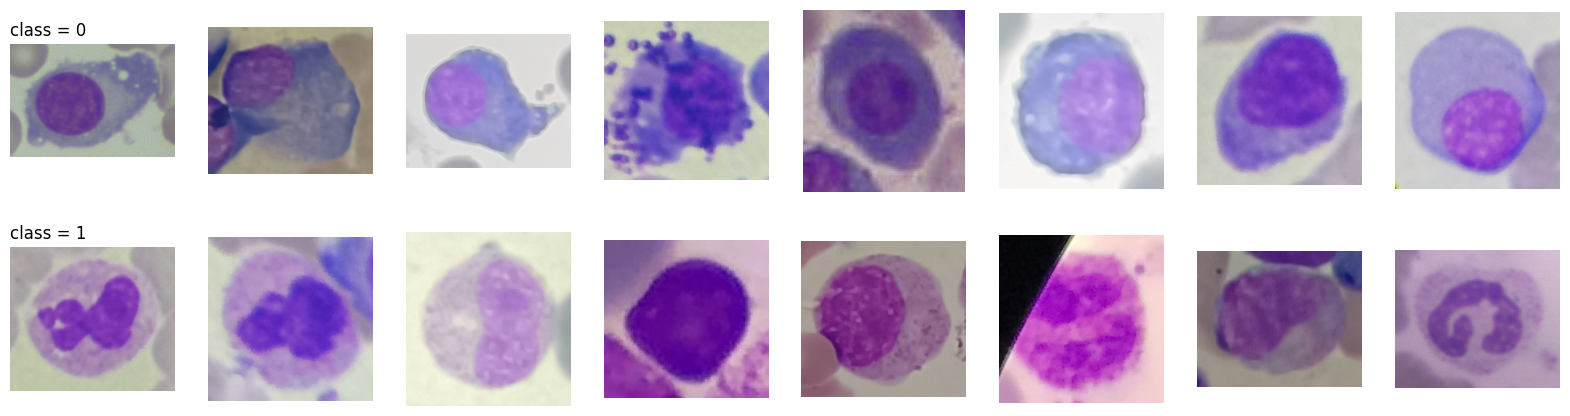

In [13]:
names = sorted(df.class_name.unique())
fig, axes = plt.subplots(len(names), 8, figsize=(20, 2.6 * len(names)), squeeze=False)
for r, n in enumerate(names):
    sample = df[df.class_name == n].sample(min(8, (df.class_name == n).sum()), random_state=0)
    for ax in axes[r]: ax.axis("off")
    for ax, p in zip(axes[r], sample.path):
        ax.imshow(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB))
    axes[r][0].set_title(f"class = {n}", loc="left")
plt.show()

**What does "positive" mean?** The public LabIA-UFBA dataset has *plasma cell* vs *non-plasma cell* labels (as far as I could tell from its description, not a separate malignant-cell label). If that's your data, plasma = positive is a proxy for myeloma cells, and your write-up should say "plasma cell classification". If your Drive copy has genuine myeloma / non-myeloma folders, use those.

In [14]:
POSITIVE_CLASS = "1"      # <- EDIT: the class_name (folder name or YOLO class id) that is the positive class
POS_NAME, NEG_NAME = "positive", "negative"     # <- optionally rename for plots, e.g. "plasma", "non-plasma"

df["label"] = (df.class_name == POSITIVE_CLASS).astype(int)
assert df.label.nunique() == 2, "Only one class found: check POSITIVE_CLASS"
print(df.label.value_counts().rename({1: POS_NAME, 0: NEG_NAME}))

label
positive    3498
negative    2074
Name: count, dtype: int64


## Step 6: Split into train (70%) / validation (15%) / test (15%)
- **train**: the model learns from it. **validation**: we watch it to pick the best epoch and stop early. **test**: touched **once**, at the very end.
- If we know which photo each cell came from (YOLO format), we keep all cells of one photo in the same split (`GroupShuffleSplit`), otherwise neighbouring cells from one photo would land in both train and test and inflate the score. In folder format there is no photo id, so we fall back to a stratified random split; say that in your write-up.

In [15]:
if df.group.notna().all():
    g = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
    a, b = next(g.split(df, df.label, df.group)); tr, tmp = df.iloc[a], df.iloc[b]
    g2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
    a, b = next(g2.split(tmp, tmp.label, tmp.group)); val, test = tmp.iloc[a], tmp.iloc[b]
    print("split by source photo")
else:
    tr, tmp = train_test_split(df, test_size=0.30, stratify=df.label, random_state=SEED)
    val, test = train_test_split(tmp, test_size=0.50, stratify=tmp.label, random_state=SEED)
    print("stratified random split (no photo ids)")
tr, val, test = tr.reset_index(drop=True), val.reset_index(drop=True), test.reset_index(drop=True)
for n, d in [("train", tr), ("val", val), ("test", test)]:
    print(f"{n:5s} {len(d):6d}   {POS_NAME}={int(d.label.sum())}   {NEG_NAME}={int((1-d.label).sum())}")

split by source photo
train   4043   positive=2579   negative=1464
val      749   positive=489   negative=260
test     780   positive=430   negative=350


## Step 7: Class weights
If one class is much rarer, the model can cheat by always guessing the common one. Class weights make mistakes on the rare class count more during training. Computed from the **training set only**.

In [16]:
n0, n1 = (tr.label == 0).sum(), (tr.label == 1).sum()
CLASS_WEIGHT = {0: len(tr) / (2 * n0), 1: len(tr) / (2 * n1)}
print(CLASS_WEIGHT)

{0: np.float64(1.3808060109289617), 1: np.float64(0.7838309422256688)}


## Step 8: Data pipeline and augmentation
- Each image is read, forced to 3 colour channels and **resized to 224x224** (VGG16's input size).
- Images are loaded in batches of 32 and prefetched so the GPU never waits.
- **Augmentation** (random flips, rotation, small zoom) runs inside the model and only while training. It is mild on purpose: we don't change colours because stain colour may matter.
- VGG16 needs its own pixel preprocessing (`preprocess_input`: convert RGB to BGR, subtract ImageNet means). It is applied inside the model so train/val/test all get it the same way.

In [17]:
SIZE, BATCH = 224, 32

def make_ds(frame, train):
    ds = tf.data.Dataset.from_tensor_slices((frame.path.values, frame.label.values.astype("float32")))
    if train: ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    def load(p, y):
        img = tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False)
        img = tf.image.resize(img, (SIZE, SIZE)); img.set_shape((SIZE, SIZE, 3))
        return img, y
    return ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(tr, True), make_ds(val, False), make_ds(test, False)

augment = keras.Sequential([layers.RandomFlip("horizontal_and_vertical"),
                            layers.RandomRotation(0.25), layers.RandomZoom(0.1)], name="augment")

## Step 9: Build VGG16
- Load VGG16 **pre-trained on ImageNet**, without its original classifier (`include_top=False`).
- **Freeze** it for now (its weights won't change yet).
- Add our own head: global average pooling, a Dense(256) layer, dropout 0.5 (randomly switches off half the units so the model doesn't memorise), and one sigmoid output = probability of the positive class.

In [18]:
def build_vgg16():
    inp = keras.Input((SIZE, SIZE, 3))
    x = augment(inp)
    x = layers.Lambda(preprocess_input, name="vgg_preprocess")(x)
    base = VGG16(include_top=False, weights="imagenet", input_shape=(SIZE, SIZE, 3))
    base.trainable = False
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inp, out, name="VGG16_classifier"), base

model, base = build_vgg16()
METRICS = [keras.metrics.BinaryAccuracy(name="acc"), keras.metrics.AUC(name="auc"),
           keras.metrics.Precision(name="prec"), keras.metrics.Recall(name="rec")]
OUT = "/content/drive/MyDrive/VGG16_results"; os.makedirs(OUT, exist_ok=True)

def cbs():
    return [keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=5, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1)]
model.summary(line_length=90)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "VGG16_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                          ┃ Output Shape                 ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)              │ (None, 224, 224, 3)          │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ augment (Sequential)                  │ (None, 224, 224, 3)          │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ vgg_preprocess (Lambda)               │ (None, 224, 224, 3)          │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ vgg16 (Functional)                    │ (None, 7, 7, 512)            │      14,714,688 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ global_average_pooling2d              │ (None, 512)                  │               0 │
│ (GlobalAveragePooling2D)              │                              │                 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ dense (Dense)                         │ (None, 256)                  │         131,328 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ dropout (Dropout)                     │ (None, 256)                  │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                       │ (None, 1)                    │             257 │
└───────────────────────────────────────┴──────────────────────────────┴─────────────────┘

 Total params: 14,846,273 (56.63 MB)

 Trainable params: 131,585 (514.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

## Step 10: Phase 1, train only the new head
VGG16's convolution layers are frozen; only our new layers learn, with a normal learning rate (1e-3). This stops random new-layer weights from wrecking the good pre-trained ones. Training stops early when validation AUC hasn't improved for 5 epochs, and the best epoch's weights are restored.

In [19]:
t0 = time.time()
model.compile(keras.optimizers.Adam(1e-3), "binary_crossentropy", metrics=METRICS)
h1 = model.fit(train_ds, validation_data=val_ds, epochs=15, class_weight=CLASS_WEIGHT, callbacks=cbs(), verbose=2)

Epoch 1/15
127/127 - 30s - 233ms/step - acc: 0.8123 - auc: 0.8905 - loss: 0.4766 - prec: 0.8879 - rec: 0.8077 - val_acc: 0.9092 - val_auc: 0.9617 - val_loss: 0.2380 - val_prec: 0.9056 - val_rec: 0.9611 - learning_rate: 0.0010
Epoch 2/15
127/127 - 19s - 148ms/step - acc: 0.8845 - auc: 0.9555 - loss: 0.2709 - prec: 0.9382 - rec: 0.8767 - val_acc: 0.9052 - val_auc: 0.9643 - val_loss: 0.2330 - val_prec: 0.8958 - val_rec: 0.9673 - learning_rate: 0.0010
Epoch 3/15
127/127 - 19s - 153ms/step - acc: 0.8998 - auc: 0.9627 - loss: 0.2479 - prec: 0.9415 - rec: 0.8988 - val_acc: 0.9212 - val_auc: 0.9676 - val_loss: 0.2171 - val_prec: 0.9232 - val_rec: 0.9591 - learning_rate: 0.0010
Epoch 4/15
127/127 - 20s - 156ms/step - acc: 0.9011 - auc: 0.9634 - loss: 0.2461 - prec: 0.9449 - rec: 0.8972 - val_acc: 0.9159 - val_auc: 0.9707 - val_loss: 0.2095 - val_prec: 0.9065 - val_rec: 0.9714 - learning_rate: 0.0010
Epoch 5/15
127/127 - 20s - 159ms/step - acc: 0.9122 - auc: 0.9702 - loss: 0.2218 - prec: 0.9517 

## Step 11: Phase 2, fine-tune the last convolution block
Now we **unfreeze `block5`** (VGG16's last 3 conv layers, the most task-specific ones) and keep the earlier blocks frozen. Learning rate drops to 1e-5, because big steps would destroy what the network already knows. Again: early stopping on validation AUC.

In [20]:
base.trainable = True
for l in base.layers:
    l.trainable = l.name.startswith("block5")
print("trainable VGG layers:", [l.name for l in base.layers if l.trainable])

model.compile(keras.optimizers.Adam(1e-5), "binary_crossentropy", metrics=METRICS)   # must recompile after changing trainable
h2 = model.fit(train_ds, validation_data=val_ds, epochs=20, class_weight=CLASS_WEIGHT, callbacks=cbs(), verbose=2)
print(f"training time: {(time.time()-t0)/60:.1f} min")

trainable VGG layers: ['block5_conv1', 'block5_conv2', 'block5_conv3', 'block5_pool']
Epoch 1/20
127/127 - 31s - 242ms/step - acc: 0.9305 - auc: 0.9792 - loss: 0.1668 - prec: 0.9515 - rec: 0.9394 - val_acc: 0.9226 - val_auc: 0.9821 - val_loss: 0.1974 - val_prec: 0.9043 - val_rec: 0.9857 - learning_rate: 1.0000e-05
Epoch 2/20
127/127 - 25s - 200ms/step - acc: 0.9456 - auc: 0.9872 - loss: 0.1429 - prec: 0.9701 - rec: 0.9438 - val_acc: 0.9159 - val_auc: 0.9828 - val_loss: 0.2201 - val_prec: 0.8944 - val_rec: 0.9877 - learning_rate: 1.0000e-05
Epoch 3/20

Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
127/127 - 40s - 316ms/step - acc: 0.9486 - auc: 0.9880 - loss: 0.1358 - prec: 0.9740 - rec: 0.9446 - val_acc: 0.9012 - val_auc: 0.9836 - val_loss: 0.2630 - val_prec: 0.8752 - val_rec: 0.9898 - learning_rate: 1.0000e-05
Epoch 4/20
127/127 - 25s - 197ms/step - acc: 0.9545 - auc: 0.9892 - loss: 0.1274 - prec: 0.9750 - rec: 0.9531 - val_acc: 0.9453 - val_auc: 0.9852 -

## Step 12: Learning curves
Training vs validation loss and AUC across both phases. The dashed line marks where fine-tuning starts. **Warning sign:** training keeps improving while validation gets worse = overfitting.

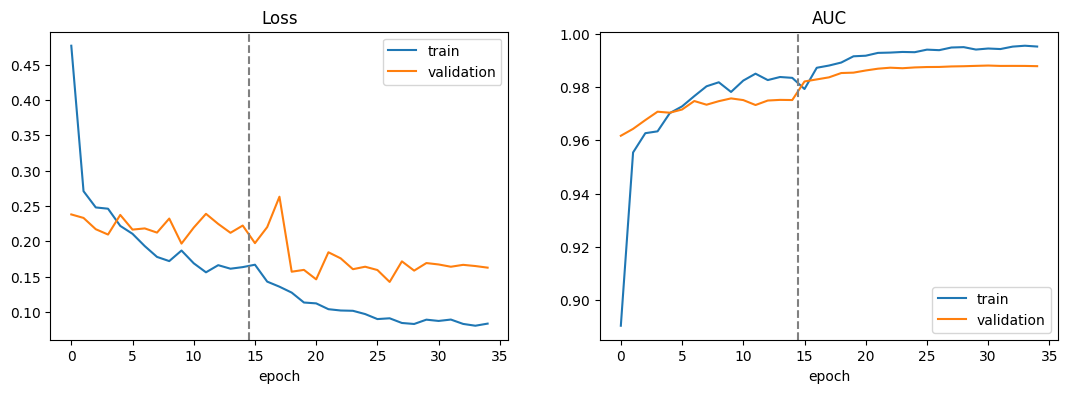

In [21]:
def cat(k): return h1.history[k] + h2.history[k]
fig, ax = plt.subplots(1, 2, figsize=(13, 4)); n1e = len(h1.history["loss"])
for a, k, t in [(ax[0], "loss", "Loss"), (ax[1], "auc", "AUC")]:
    a.plot(cat(k), label="train"); a.plot(cat("val_" + k), label="validation")
    a.axvline(n1e - 0.5, ls="--", c="grey"); a.set_title(t); a.set_xlabel("epoch"); a.legend()
plt.savefig(f"{OUT}/curves.png", bbox_inches="tight"); plt.show()

## Step 13: Test-set evaluation (the one time we touch the test set)
We predict a probability for every test cell and call it positive if it's >= 0.5. We report accuracy, precision (of the cells we called positive, how many really were), recall (of the real positives, how many we found), F1, and AUC (ranking quality, independent of the 0.5 cut-off). Plus the confusion matrix and ROC curve.

              precision    recall  f1-score   support

    negative     0.9466    0.9114    0.9287       350
    positive     0.9300    0.9581    0.9439       430

    accuracy                         0.9372       780
   macro avg     0.9383    0.9348    0.9363       780
weighted avg     0.9375    0.9372    0.9371       780

{'accuracy': 0.9372, 'precision': 0.93, 'recall': 0.9581, 'f1': 0.9439, 'auc': np.float64(0.986), 'n_train': 4043, 'n_val': 749, 'n_test': 780}


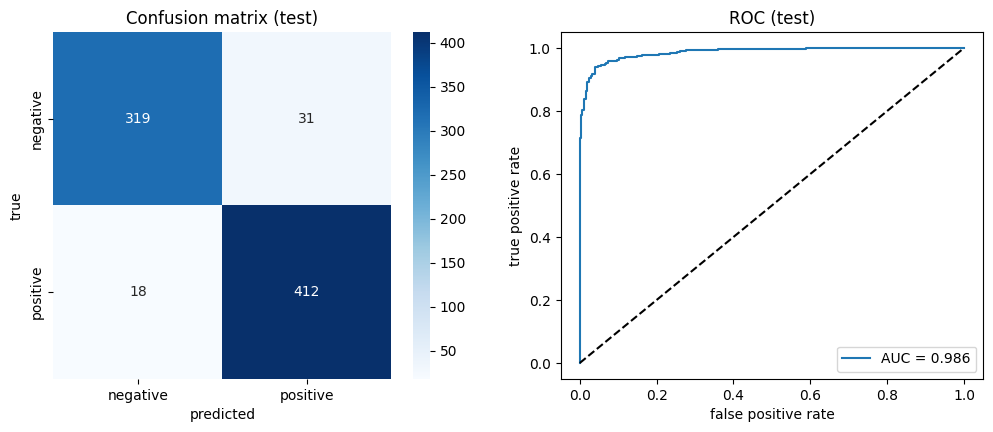

In [22]:
y_true = test.label.values
y_prob = model.predict(test_ds, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print(classification_report(y_true, y_pred, target_names=[NEG_NAME, POS_NAME], digits=4))
res = dict(accuracy=accuracy_score(y_true, y_pred), precision=precision_score(y_true, y_pred),
           recall=recall_score(y_true, y_pred), f1=f1_score(y_true, y_pred), auc=roc_auc_score(y_true, y_prob),
           n_train=len(tr), n_val=len(val), n_test=len(test))
print({k: round(v, 4) if isinstance(v, float) else v for k, v in res.items()})

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt="d", cmap="Blues", ax=ax[0],
            xticklabels=[NEG_NAME, POS_NAME], yticklabels=[NEG_NAME, POS_NAME])
ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true"); ax[0].set_title("Confusion matrix (test)")
fpr, tpr, _ = roc_curve(y_true, y_prob)
ax[1].plot(fpr, tpr, label=f"AUC = {res['auc']:.3f}"); ax[1].plot([0, 1], [0, 1], "k--")
ax[1].set_xlabel("false positive rate"); ax[1].set_ylabel("true positive rate"); ax[1].set_title("ROC (test)"); ax[1].legend()
plt.savefig(f"{OUT}/test_eval.png", bbox_inches="tight"); plt.show()

## Step 14: Look at the mistakes
Numbers hide *why* a model fails. We show up to 8 false positives and 8 false negatives. If errors are blurry crops, tiny boxes or cells that look ambiguous, that's useful to write about.

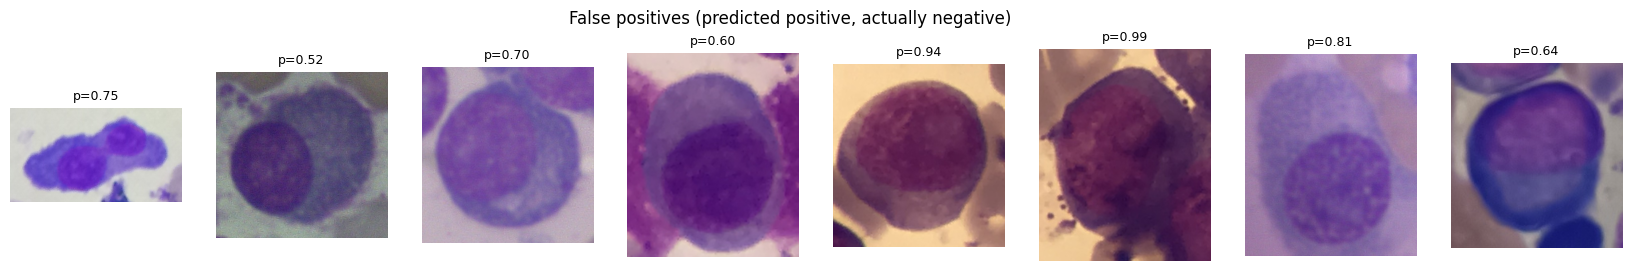

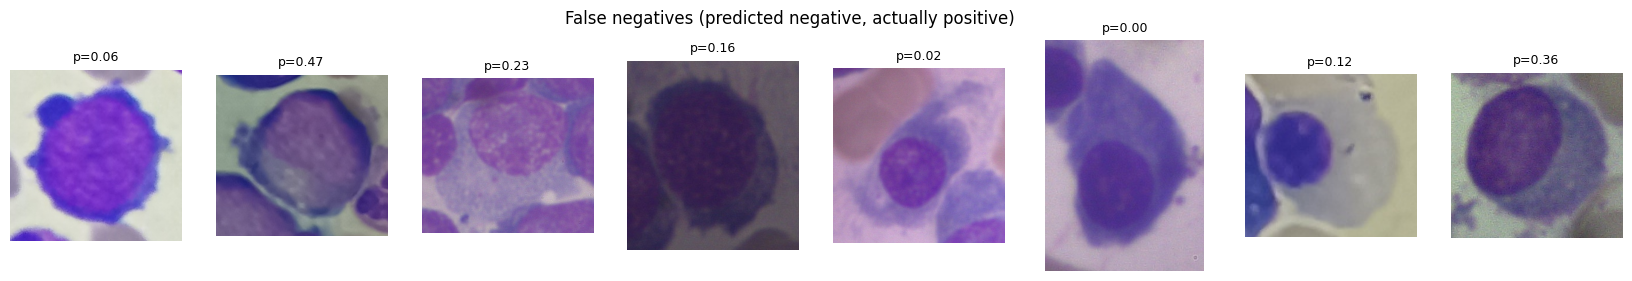

In [23]:
test["prob"] = y_prob; test["pred"] = y_pred
for title, sub in [("False positives (predicted positive, actually negative)", test[(test.pred == 1) & (test.label == 0)]),
                   ("False negatives (predicted negative, actually positive)", test[(test.pred == 0) & (test.label == 1)])]:
    sub = sub.sample(min(8, len(sub)), random_state=0) if len(sub) else sub
    fig, axes = plt.subplots(1, max(len(sub), 1), figsize=(2.6 * max(len(sub), 1), 3), squeeze=False)
    for ax, (_, r) in zip(axes[0], sub.iterrows()):
        ax.imshow(cv2.cvtColor(cv2.imread(r.path), cv2.COLOR_BGR2RGB)); ax.axis("off"); ax.set_title(f"p={r.prob:.2f}", fontsize=9)
    fig.suptitle(title); plt.show()

## Step 15: Save everything to Drive
Saved: the model weights (rebuild the model with `build_vgg16()` then `model.load_weights(...)`), the metrics as JSON, and the split lists so the exact same train/val/test can be reproduced.

In [24]:
model.save_weights(f"{OUT}/vgg16.weights.h5")
json.dump(res, open(f"{OUT}/test_metrics.json", "w"), indent=2)
for n, d in [("train", tr), ("val", val), ("test", test)]:
    d[["path", "class_name", "label", "group"]].to_csv(f"{OUT}/split_{n}.csv", index=False)
print("saved to", OUT)

saved to /content/drive/MyDrive/VGG16_results


## For the write-up
- State exactly what the two classes are (see Step 5) and how many images are in each split.
- Say how the split was made (by source photo or random) and that the test set was used once.
- One run is one sample. For a stronger claim, repeat with 3 different `SEED` values and report mean ± std.
- Report recall as well as accuracy: it tells you how many positive cells were missed.
- Your choices (ImageNet weights, two phases, block5 unfrozen, augmentation, 224 px) are *design decisions*; list them.